# Текущий контроль 9. Нейронная сеть «с нуля»: обратное распространение ошибки на PyTorch

**Задание.** 1) Разобраться с материалом (нейрон, слой, функции активации, функции потерь, градиентный спуск, обратное распространение ошибки). 2) Создать и обучить нейронную сеть, датасет выбирается произвольно.

**Что сделано в работе.**

1. Кратко разобрана теория: от нейрона до обратного распространения ошибки.
2. Выбран датасет `load_digits` из scikit-learn: 1797 изображений рукописных цифр размером 8×8 пикселей, 10 классов. Данные разбиты на обучающую, валидационную и тестовую части.
3. Сеть 64 → 64 → 32 → 10 написана «с нуля» на тензорах PyTorch **без autograd**: классы `Dense`, `Activation_ReLU`, `Softmax_CrossEntropy` с ручными `forward` и `backward`, как в материале, а также простой оптимизатор `SGD` (с momentum).
4. Ручные градиенты сверены с `torch.autograd` на одном мини-батче.
5. Сеть обучена, качество оценено на тестовой выборке (accuracy, матрица ошибок, precision/recall/F1 по классам, примеры ошибок).
6. Результат сравнён с той же сетью на `torch.nn.Sequential` + `torch.optim.SGD` и с простыми моделями из scikit-learn.
7. Кратко проверено влияние скорости обучения и размера батча.

## 1. Теория

### 1.1 Нейрон и слой

Нейрон получает вектор входов $\mathbf{x}=(x_1,\dots,x_n)$, считает взвешенную сумму и прибавляет смещение (bias):

$$z=\mathbf{w}^{\top}\mathbf{x}+b=\sum_{j=1}^{n}w_jx_j+b,\qquad a=f(z),$$

где $f$ — функция активации. Без неё сеть из любого числа слоёв оставалась бы одной линейной функцией.

Слой из $m$ нейронов обрабатывает сразу пакет (batch) из $N$ объектов. Если $X\in\mathbb{R}^{N\times n}$ — матрица входов, $W\in\mathbb{R}^{n\times m}$ — матрица весов, $\mathbf{b}\in\mathbb{R}^{m}$ — смещения, то

$$Z=XW+\mathbf{b},\qquad Z\in\mathbb{R}^{N\times m},$$

причём вектор $\mathbf{b}$ прибавляется к каждой строке. Именно так устроен `forward` у класса `Dense` в материале: `inputs @ weights + biases`.

### 1.2 Функции активации

**ReLU** обнуляет отрицательные значения:

$$\mathrm{ReLU}(z)=\max(0,z),\qquad \mathrm{ReLU}'(z)=\begin{cases}1,& z>0,\\ 0,& z\le 0.\end{cases}$$

**Softmax** на выходе превращает $K$ чисел (логитов) $z_1,\dots,z_K$ в вероятности классов:

$$p_k=\frac{e^{z_k}}{\sum_{j=1}^{K}e^{z_j}},\qquad p_k>0,\quad \sum_k p_k=1.$$

Чтобы экспонента не переполнялась, из всех логитов объекта предварительно вычитают их максимум. Вероятности при этом не меняются.

### 1.3 Функция потерь

Для классификации используется **кросс-энтропия**. Пусть $y_{ik}$ равно 1, если $i$-й объект принадлежит классу $k$, и 0 иначе (one-hot кодирование), а $y_i$ — номер верного класса. Тогда для пакета из $N$ объектов

$$L=-\frac{1}{N}\sum_{i=1}^{N}\sum_{k=1}^{K}y_{ik}\log p_{ik}=-\frac{1}{N}\sum_{i=1}^{N}\log p_{i,\,y_i}.$$

Чем больше вероятность, отданная верному классу, тем меньше потери. Если сеть «не знает» ответа и выдаёт всем 10 классам одинаковые вероятности $0{,}1$, то $L=\ln 10\approx 2{,}30$. У необученной сети со случайными весами потери получаются порядка этой величины.

### 1.4 Обратное распространение ошибки

Сеть — это композиция функций. Для нашей сети с двумя скрытыми слоями

$$\begin{aligned}
Z_1&=XW_1+\mathbf{b}_1, & A_1&=\mathrm{ReLU}(Z_1),\\
Z_2&=A_1W_2+\mathbf{b}_2, & A_2&=\mathrm{ReLU}(Z_2),\\
Z_3&=A_2W_3+\mathbf{b}_3, & L&=\mathrm{CE}\bigl(\mathrm{softmax}(Z_3),\,Y\bigr).
\end{aligned}$$

Градиент нужен по всем $W_l$ и $\mathbf{b}_l$. Его считают по **цепному правилу**, двигаясь от потерь к входу: градиент по параметрам слоя равен градиенту, пришедшему от следующего слоя, умноженному на локальную производную. Поэтому каждому слою достаточно знать две вещи: градиент $G=\partial L/\partial Z$ (в коде — `dvalues`) и то, что он запомнил на прямом проходе (свои входы). Устройство соседних слоёв знать не нужно, из-за этого слои можно собирать как конструктор.

**Полносвязный слой.** Пусть известен $G=\partial L/\partial Z\in\mathbb{R}^{N\times m}$. Так как $Z_{ik}=\sum_j X_{ij}W_{jk}+b_k$, то

$$\frac{\partial L}{\partial W}=X^{\top}G,\qquad \frac{\partial L}{\partial \mathbf{b}}=\sum_{i=1}^{N}G_{i\cdot},\qquad \frac{\partial L}{\partial X}=G\,W^{\top}.$$

Последняя матрица — это градиент, который слой передаёт предыдущему (`dinputs`).

**ReLU.** Производная равна 1 там, где вход положителен, и 0 в остальных местах, поэтому

$$\frac{\partial L}{\partial Z}=G\odot[Z>0],$$

где $\odot$ — поэлементное произведение, а $[Z>0]$ — матрица из нулей и единиц.

**Softmax + кросс-энтропия.** Для одного объекта с верным классом $y$ потери можно записать как $L=-z_y+\log\sum_{j}e^{z_j}$. Дифференцируем по логиту $z_k$:

$$\frac{\partial L}{\partial z_k}=-[k=y]+\frac{e^{z_k}}{\sum_j e^{z_j}}=p_k-[k=y].$$

Для пакета из $N$ объектов с усреднением потерь получаем

$$\frac{\partial L}{\partial Z_3}=\frac{P-Y}{N},$$

где $P$ — матрица вероятностей, $Y$ — one-hot матрица ответов. Эта простая формула — причина, по которой softmax и кросс-энтропию реализуют одним классом.

**Итог для нашей сети.** Обратный проход идёт справа налево:

$$\begin{aligned}
G_3&=\frac{P-Y}{N}, & \frac{\partial L}{\partial W_3}&=A_2^{\top}G_3, & \frac{\partial L}{\partial \mathbf{b}_3}&=\sum_i (G_3)_{i\cdot},\\
G_2&=\bigl(G_3W_3^{\top}\bigr)\odot[Z_2>0], & \frac{\partial L}{\partial W_2}&=A_1^{\top}G_2, & \frac{\partial L}{\partial \mathbf{b}_2}&=\sum_i (G_2)_{i\cdot},\\
G_1&=\bigl(G_2W_2^{\top}\bigr)\odot[Z_1>0], & \frac{\partial L}{\partial W_1}&=X^{\top}G_1, & \frac{\partial L}{\partial \mathbf{b}_1}&=\sum_i (G_1)_{i\cdot}.
\end{aligned}$$

Здесь $G_l=\partial L/\partial Z_l$ — градиент, который пришёл к $l$-му слою.

`torch.autograd` строит граф вычислений и делает то же самое автоматически (метод `.backward()`). Ниже мы реализуем формулы вручную и затем сверим результат с autograd.

### 1.5 Градиентный спуск по мини-батчам

Параметры $\theta$ (все веса и смещения) сдвигаются против градиента, посчитанного по мини-батчу:

$$\theta\leftarrow\theta-\eta\,\nabla_{\theta}L_{\text{batch}}.$$

Здесь $\eta$ — скорость обучения (learning rate). Можно добавить инерцию (momentum) с коэффициентом $\mu$ — в той форме, в какой она записана в `torch.optim.SGD`:

$$v\leftarrow\mu v+\nabla_{\theta}L_{\text{batch}},\qquad \theta\leftarrow\theta-\eta\,v.$$

При $\mu=0$ получается обычный SGD. **Эпоха** — один проход по всем объектам обучающей выборки; перед каждой эпохой объекты перемешиваются и режутся на батчи.

### 1.6 Инициализация весов

Смещения обнуляем. Веса перед ReLU задаём по **He**: $w\sim\mathcal{N}\bigl(0,\,2/n_{in}\bigr)$, где $n_{in}$ — число входов слоя. Веса выходного слоя — по **Xavier**: $w\sim\mathcal{N}\bigl(0,\,2/(n_{in}+n_{out})\bigr)$. Идея в обоих случаях одна: дисперсия сигналов не должна расти или затухать от слоя к слою.

## 2. Данные

### 2.1 Подготовка окружения

In [1]:
import copy
import time
import warnings

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

torch.manual_seed(0)
np.random.seed(0)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

print("torch", torch.__version__, "| устройство: CPU")

torch 2.14.1 | устройство: CPU


### 2.2 Описание датасета

`sklearn.datasets.load_digits` — это 1797 изображений рукописных цифр (набор «Optical Recognition of Handwritten Digits» из репозитория UCI). Каждое изображение — матрица 8×8, то есть **64 признака**; значение пикселя — целое число от 0 (фон) до 16 (максимальная яркость). Задача — многоклассовая классификация на 10 классов (цифры 0–9). Файлы скачивать не нужно, данные поставляются вместе со scikit-learn.

In [2]:
digits = load_digits()
X_all, y_all = digits.data, digits.target

print("Форма X:", X_all.shape, "| форма y:", y_all.shape)
print("Значения пикселей: от", X_all.min(), "до", X_all.max())
print("Пропусков:", int(np.isnan(X_all).sum()))
print("Объектов в каждом классе:", dict(zip(*np.unique(y_all, return_counts=True))))

Форма X: (1797, 64) | форма y: (1797,)
Значения пикселей: от 0.0 до 16.0
Пропусков: 0
Объектов в каждом классе: {np.int64(0): np.int64(178), np.int64(1): np.int64(182), np.int64(2): np.int64(177), np.int64(3): np.int64(183), np.int64(4): np.int64(181), np.int64(5): np.int64(182), np.int64(6): np.int64(181), np.int64(7): np.int64(179), np.int64(8): np.int64(174), np.int64(9): np.int64(180)}


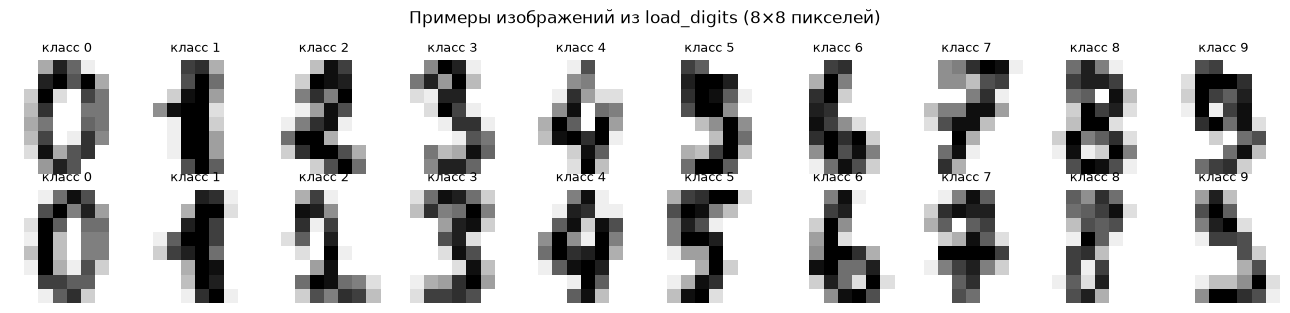

In [3]:
# По два примера каждой цифры: столбец = класс
fig, axes = plt.subplots(2, 10, figsize=(13, 3.2))
for digit in range(10):
    idx = np.where(y_all == digit)[0][:2]
    for row, i in enumerate(idx):
        ax = axes[row, digit]
        ax.imshow(digits.images[i], cmap="gray_r")
        ax.set_title(f"класс {digit}", fontsize=9)
        ax.axis("off")
fig.suptitle("Примеры изображений из load_digits (8×8 пикселей)")
plt.tight_layout()
plt.show()

### 2.3 Разбиение и нормировка

Делим данные на три части: **60 % — обучение (train)**, **20 % — валидация (val)**, **20 % — тест (test)**. Разбиение стратифицированное (доли классов сохраняются) и с фиксированным `random_state`. Валидационная выборка нужна, чтобы следить за обучением и подбирать гиперпараметры; **по тестовой выборке гиперпараметры не подбираются, итоговая оценка основной модели делается один раз**.

Пиксели лежат в диапазоне 0…16, поэтому для нормировки делим их на 16, получаем значения 0…1. Делитель — известная константа, а не статистика выборки, так что утечки информации из val/test в train нет.

In [4]:
X_trainval, X_te, y_trainval, y_te = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=42)
X_tr, X_va, y_tr, y_va = train_test_split(
    X_trainval, y_trainval, test_size=0.25, stratify=y_trainval, random_state=42)

# Нормировка 0..16 -> 0..1 и перевод в тензоры PyTorch
X_tr, X_va, X_te = [torch.tensor(a / 16.0, dtype=torch.float32) for a in (X_tr, X_va, X_te)]
y_tr, y_va, y_te = [torch.tensor(a, dtype=torch.long) for a in (y_tr, y_va, y_te)]

counts = pd.DataFrame({
    "train": np.bincount(y_tr.numpy(), minlength=10),
    "val": np.bincount(y_va.numpy(), minlength=10),
    "test": np.bincount(y_te.numpy(), minlength=10),
}).T
counts.columns = [f"класс {c}" for c in range(10)]
counts["всего"] = counts.sum(axis=1)

print("train:", tuple(X_tr.shape), "| val:", tuple(X_va.shape), "| test:", tuple(X_te.shape))
print("Диапазон признаков после нормировки: от", X_tr.min().item(), "до", X_tr.max().item())
counts

train: (1077, 64) | val: (360, 64) | test: (360, 64)
Диапазон признаков после нормировки: от 0.0 до 1.0


,класс 0,класс 1,класс 2,класс 3,класс 4,класс 5,класс 6,класс 7,класс 8,класс 9,всего
train,106,109,107,109,109,109,109,107,104,108,1077
val,36,37,35,37,36,36,36,36,35,36,360
test,36,36,35,37,36,37,36,36,35,36,360


## 3. Нейронная сеть «с нуля» (ручное обратное распространение)

Реализуем классы так же, как в материале: у каждого есть `forward`, который запоминает входы, и `backward`, который по пришедшему градиенту `dvalues` считает `dweights`, `dbiases` и `dinputs`. Все тензоры создаются **без** `requires_grad`, то есть autograd в обучении не участвует: каждую производную мы выписали сами в разделе 1.4.

In [5]:
class Dense:
    # Полносвязный слой: Z = X @ W + b
    def __init__(self, n_inputs, n_neurons, init="he", generator=None):
        if init == "he":                       # для слоёв перед ReLU
            std = (2.0 / n_inputs) ** 0.5
        elif init == "xavier":                 # для выходного слоя
            std = (2.0 / (n_inputs + n_neurons)) ** 0.5
        else:
            raise ValueError(init)
        self.weights = torch.randn(n_inputs, n_neurons, generator=generator) * std
        self.biases = torch.zeros(n_neurons)

    def forward(self, inputs):
        self.inputs = inputs                   # понадобятся в backward
        return inputs @ self.weights + self.biases

    def backward(self, dvalues):
        self.dweights = self.inputs.T @ dvalues        # dL/dW = X^T G
        self.dbiases = dvalues.sum(dim=0)              # dL/db = сумма G по объектам
        self.dinputs = dvalues @ self.weights.T        # dL/dX = G W^T


class Activation_ReLU:
    def forward(self, inputs):
        self.inputs = inputs
        return inputs.clamp(min=0)

    def backward(self, dvalues):
        self.dinputs = dvalues.clone()
        self.dinputs[self.inputs <= 0] = 0             # градиент не проходит там, где вход <= 0


class Softmax_CrossEntropy:
    # Softmax и кросс-энтропия в одном классе: backward получается простым (p - y) / N
    def forward(self, logits, y_true):
        shifted = logits - logits.max(dim=1, keepdim=True).values      # устойчивость
        log_probs = shifted - torch.log(torch.exp(shifted).sum(dim=1, keepdim=True))
        self.probs = torch.exp(log_probs)
        self.y_true = y_true
        n = logits.shape[0]
        return -log_probs[torch.arange(n), y_true].mean()

    def backward(self):
        n = self.probs.shape[0]
        self.dinputs = self.probs.clone()
        self.dinputs[torch.arange(n), self.y_true] -= 1                 # p - y (one-hot)
        self.dinputs /= n                                               # усреднение по батчу
        return self.dinputs


class SGD:
    # Градиентный спуск; momentum=0 даёт обычный SGD. Формулы как в torch.optim.SGD
    def __init__(self, lr, momentum=0.0):
        self.lr = lr
        self.momentum = momentum
        self.velocity = None

    def step(self, dense_layers):
        if self.velocity is None:
            self.velocity = [(torch.zeros_like(l.weights), torch.zeros_like(l.biases))
                             for l in dense_layers]
        for layer, (vw, vb) in zip(dense_layers, self.velocity):
            vw.mul_(self.momentum).add_(layer.dweights)
            vb.mul_(self.momentum).add_(layer.dbiases)
            layer.weights -= self.lr * vw
            layer.biases -= self.lr * vb


class MLP:
    # Цепочка слоёв Dense -> ReLU -> Dense -> ReLU -> ... -> Dense (логиты)
    def __init__(self, sizes, generator=None):
        self.layers = []
        for i in range(len(sizes) - 1):
            last = i == len(sizes) - 2
            self.layers.append(Dense(sizes[i], sizes[i + 1],
                                     init="xavier" if last else "he", generator=generator))
            if not last:
                self.layers.append(Activation_ReLU())
        self.dense = [l for l in self.layers if isinstance(l, Dense)]

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def backward(self, dvalues):
        for layer in reversed(self.layers):
            layer.backward(dvalues)
            dvalues = layer.dinputs

    def n_params(self):
        return sum(l.weights.numel() + l.biases.numel() for l in self.dense)

Архитектура **64 → 64 → 32 → 10**: 64 входных пикселя, два скрытых слоя с ReLU (64 и 32 нейрона) и 10 выходных логитов, по одному на цифру. Функцию `make_net` используем везде, где нужна сеть с воспроизводимой начальной инициализацией.

In [6]:
SIZES = (64, 64, 32, 10)


def make_net(seed):
    return MLP(SIZES, generator=torch.Generator().manual_seed(seed))


net = make_net(0)

rows = []
for i, l in enumerate(net.dense, 1):
    rows.append({"слой": f"Dense {i}", "форма весов": tuple(l.weights.shape),
                 "весов": l.weights.numel(), "смещений": l.biases.numel(),
                 "всего": l.weights.numel() + l.biases.numel()})
print(pd.DataFrame(rows).to_string(index=False))
print("Всего обучаемых параметров:", net.n_params())

# Проверка здравого смысла: потери необученной сети должны быть порядка ln(10) = 2.30 (так было бы при равных вероятностях)
logits = net.forward(X_tr)
print("Потери необученной сети на train:", round(Softmax_CrossEntropy().forward(logits, y_tr).item(), 4),
      "| ln(10) =", round(float(np.log(10)), 4))

   слой форма весов  весов  смещений  всего
Dense 1    (64, 64)   4096        64   4160
Dense 2    (64, 32)   2048        32   2080
Dense 3    (32, 10)    320        10    330
Всего обучаемых параметров: 6570
Потери необученной сети на train: 2.5715 | ln(10) = 2.3026


## 4. Проверка корректности обратного распространения

Прежде чем обучать сеть, убедимся, что формулы из раздела 1.4 реализованы верно. Берём один мини-батч из 32 объектов, считаем градиенты вручную и теми же весами — через `torch.autograd` (`F.cross_entropy` + `.backward()`), затем сравниваем. Проверка делается в `float32` (в этой точности сеть и обучается) и в `float64`: во втором случае остаточная разница показывает чистую ошибку формул, без шума округления.

In [7]:
def manual_grads(net, X, y, dtype):
    # Ручные градиенты на копии сети, приведённой к нужной точности
    net_c = copy.deepcopy(net)
    for l in net_c.dense:
        l.weights, l.biases = l.weights.to(dtype), l.biases.to(dtype)
    loss_fn = Softmax_CrossEntropy()
    loss = loss_fn.forward(net_c.forward(X.to(dtype)), y)
    net_c.backward(loss_fn.backward())
    return loss.item(), [(l.dweights, l.dbiases) for l in net_c.dense]


def autograd_grads(net, X, y, dtype):
    # Те же веса, но градиенты считает torch.autograd
    params = [(l.weights.to(dtype).clone().requires_grad_(True),
               l.biases.to(dtype).clone().requires_grad_(True)) for l in net.dense]
    h = X.to(dtype)
    for i, (W, b) in enumerate(params):
        h = h @ W + b
        if i < len(params) - 1:
            h = torch.relu(h)
    loss = torch.nn.functional.cross_entropy(h, y)
    loss.backward()
    return loss.item(), [(W.grad, b.grad) for W, b in params]


Xb, yb = X_tr[:32], y_tr[:32]
rows = []
for dtype in (torch.float32, torch.float64):
    loss_m, g_m = manual_grads(net, Xb, yb, dtype)
    loss_a, g_a = autograd_grads(net, Xb, yb, dtype)
    for i, ((dW_m, db_m), (dW_a, db_a)) in enumerate(zip(g_m, g_a), 1):
        rows.append({"точность": str(dtype).replace("torch.", ""), "слой": f"Dense {i}",
                     "max|ΔdW|": (dW_m - dW_a).abs().max().item(),
                     "max|Δdb|": (db_m - db_a).abs().max().item(),
                     "max|dW| (масштаб)": dW_a.abs().max().item(),
                     "|Δ loss|": abs(loss_m - loss_a)})
check = pd.DataFrame(rows)
pd.options.display.float_format = "{:.3e}".format
print(check.to_string(index=False))

for name in ("float32", "float64"):
    part = check[check["точность"] == name]
    print(f"{name}: максимум абсолютной разницы градиентов = {max(part['max|ΔdW|'].max(), part['max|Δdb|'].max()):.3e}")
pd.reset_option("display.float_format")

точность    слой  max|ΔdW|  max|Δdb|  max|dW| (масштаб)  |Δ loss|
 float32 Dense 1 7.451e-09 7.451e-09          1.106e-01 0.000e+00
 float32 Dense 2 1.490e-08 1.490e-08          2.810e-01 0.000e+00
 float32 Dense 3 1.490e-08 7.451e-09          2.097e-01 0.000e+00
 float64 Dense 1 1.388e-17 1.388e-17          1.106e-01 4.441e-16
 float64 Dense 2 2.776e-17 2.776e-17          2.810e-01 4.441e-16
 float64 Dense 3 1.388e-17 2.776e-17          2.097e-01 4.441e-16
float32: максимум абсолютной разницы градиентов = 1.490e-08
float64: максимум абсолютной разницы градиентов = 2.776e-17


## 5. Обучение сети

Гиперпараметры: мини-батч 32 объекта, SGD с momentum 0,9, скорость обучения 0,05, 60 эпох. Значения выбраны ориентировочно по валидационной выборке (сами пробные запуски в ноутбук не включены); тестовая выборка в подборе не участвовала. Основная конфигурация затем сравнивается с другими в разделе 8 на той же валидации, поэтому её val-показатели слегка оптимистичны. Чувствительность к `lr` и размеру батча отдельно разобрана в разделе 8. После каждой эпохи считаем потери и accuracy на всей обучающей и на всей валидационной выборках (без обновления весов); в журнал выводим первую эпоху и каждую десятую.

In [8]:
def evaluate(net, X, y):
    logits = net.forward(X)
    loss = Softmax_CrossEntropy().forward(logits, y).item()
    acc = (logits.argmax(dim=1) == y).float().mean().item()
    return loss, acc


def fit(net, optimizer, epochs, batch_size, seed, log_every=10):
    loss_fn = Softmax_CrossEntropy()
    gen = torch.Generator().manual_seed(seed)          # порядок батчей воспроизводим по seed
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    n = X_tr.shape[0]
    for epoch in range(1, epochs + 1):
        perm = torch.randperm(n, generator=gen)
        for start in range(0, n, batch_size):
            idx = perm[start:start + batch_size]
            logits = net.forward(X_tr[idx])            # прямой проход
            loss_fn.forward(logits, y_tr[idx])
            net.backward(loss_fn.backward())           # обратный проход
            optimizer.step(net.dense)                  # шаг градиентного спуска
        tl, ta = evaluate(net, X_tr, y_tr)
        vl, va = evaluate(net, X_va, y_va)
        for key, value in zip(hist, (tl, vl, ta, va)):
            hist[key].append(value)
        if log_every and (epoch == 1 or epoch % log_every == 0):
            print(f"эпоха {epoch:3d} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}")
    return hist


LR, MOMENTUM, BATCH, EPOCHS, SEED = 0.05, 0.9, 32, 60, 0

net = make_net(SEED)
t0 = time.perf_counter()
hist = fit(net, SGD(LR, MOMENTUM), EPOCHS, BATCH, SEED)
print(f"Время обучения: {time.perf_counter() - t0:.1f} с")

эпоха   1 | train loss 0.5018 acc 0.8319 | val loss 0.5600 acc 0.8194


эпоха  10 | train loss 0.0318 acc 0.9870 | val loss 0.1129 acc 0.9667
эпоха  20 | train loss 0.0025 acc 1.0000 | val loss 0.0603 acc 0.9778
эпоха  30 | train loss 0.0014 acc 1.0000 | val loss 0.0589 acc 0.9806


эпоха  40 | train loss 0.0010 acc 1.0000 | val loss 0.0581 acc 0.9833


эпоха  50 | train loss 0.0007 acc 1.0000 | val loss 0.0594 acc 0.9833
эпоха  60 | train loss 0.0006 acc 1.0000 | val loss 0.0591 acc 0.9833
Время обучения: 0.3 с


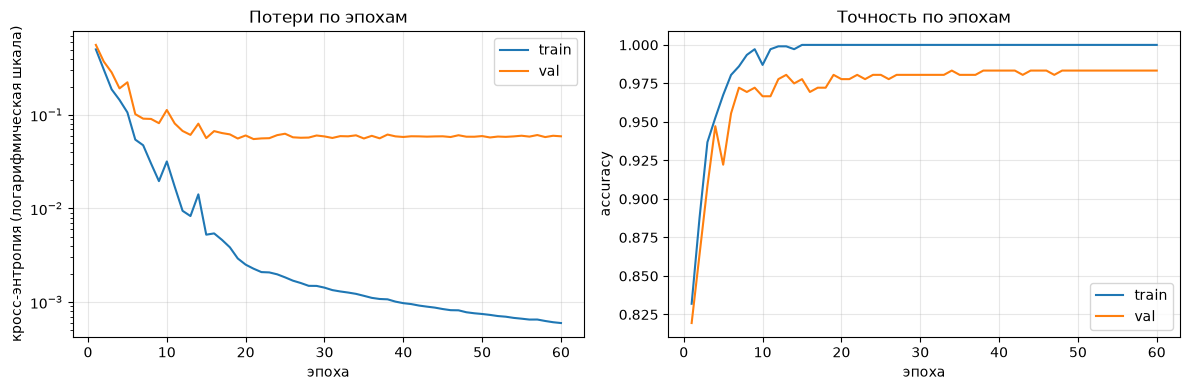

Минимум val loss 0.0552 достигнут на эпохе 21; на эпохе 60 val loss = 0.0591
Первая эпоха с train accuracy = 1.0: 15
Итог на эпохе 60: train acc 1.0000, val acc 0.9833, разрыв 0.0167


In [9]:
epochs_axis = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_axis, hist["train_loss"], label="train")
axes[0].plot(epochs_axis, hist["val_loss"], label="val")
axes[0].set_yscale("log")
axes[0].set_xlabel("эпоха")
axes[0].set_ylabel("кросс-энтропия (логарифмическая шкала)")
axes[0].set_title("Потери по эпохам")
axes[0].legend()

axes[1].plot(epochs_axis, hist["train_acc"], label="train")
axes[1].plot(epochs_axis, hist["val_acc"], label="val")
axes[1].set_xlabel("эпоха")
axes[1].set_ylabel("accuracy")
axes[1].set_title("Точность по эпохам")
axes[1].legend()

plt.tight_layout()
plt.show()

best = int(np.argmin(hist["val_loss"])) + 1
print(f"Минимум val loss {min(hist['val_loss']):.4f} достигнут на эпохе {best}; на эпохе {EPOCHS} val loss = {hist['val_loss'][-1]:.4f}")
first_full = next((i + 1 for i, a in enumerate(hist["train_acc"]) if a == 1.0), None)
print("Первая эпоха с train accuracy = 1.0:", first_full)
print(f"Итог на эпохе {EPOCHS}: train acc {hist['train_acc'][-1]:.4f}, val acc {hist['val_acc'][-1]:.4f}, "
      f"разрыв {hist['train_acc'][-1] - hist['val_acc'][-1]:.4f}")

## 6. Итоговая оценка на тестовой выборке

Для основной (обученной вручную) модели тестовая выборка использовалась только здесь, один раз. Гиперпараметры по ней не подбирались; сравнения в разделе 7 тоже считаются на тесте, но выбор по ним не делался.

In [10]:
logits_te = net.forward(X_te)
pred_te = logits_te.argmax(dim=1)
y_te_np, pred_te_np = y_te.numpy(), pred_te.numpy()

acc_te = accuracy_score(y_te_np, pred_te_np)
n_err = int((y_te_np != pred_te_np).sum())
print(f"Accuracy на test: {acc_te:.4f}  (ошибок: {n_err} из {len(y_te_np)})\n")
print(classification_report(y_te_np, pred_te_np, digits=3))

Accuracy на test: 0.9694  (ошибок: 11 из 360)

              precision    recall  f1-score   support

           0      1.000     0.972     0.986        36
           1      0.917     0.917     0.917        36
           2      1.000     1.000     1.000        35
           3      1.000     0.973     0.986        37
           4      0.923     1.000     0.960        36
           5      0.974     1.000     0.987        37
           6      1.000     1.000     1.000        36
           7      0.973     1.000     0.986        36
           8      0.912     0.886     0.899        35
           9      1.000     0.944     0.971        36

    accuracy                          0.969       360
   macro avg      0.970     0.969     0.969       360
weighted avg      0.970     0.969     0.969       360



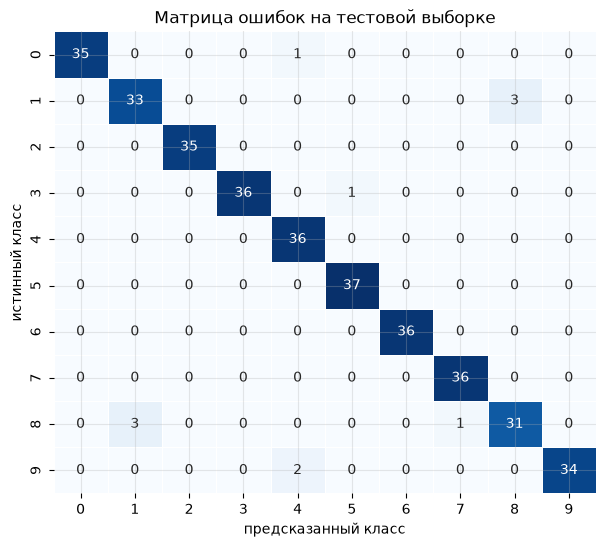

Ошибки (истина -> предсказано: число объектов):
  1 -> 8: 3
  8 -> 1: 3
  9 -> 4: 2
  0 -> 4: 1
  3 -> 5: 1
  8 -> 7: 1


In [11]:
cm = confusion_matrix(y_te_np, pred_te_np, labels=range(10))

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=0.5, linecolor="white",
            xticklabels=range(10), yticklabels=range(10))
plt.xlabel("предсказанный класс")
plt.ylabel("истинный класс")
plt.title("Матрица ошибок на тестовой выборке")
plt.show()

# Самые частые путаницы (вне диагонали)
pairs = [(int(i), int(j), int(cm[i, j])) for i in range(10) for j in range(10) if i != j and cm[i, j] > 0]
pairs.sort(key=lambda t: -t[2])
print("Ошибки (истина -> предсказано: число объектов):")
for i, j, c in pairs:
    print(f"  {i} -> {j}: {c}")

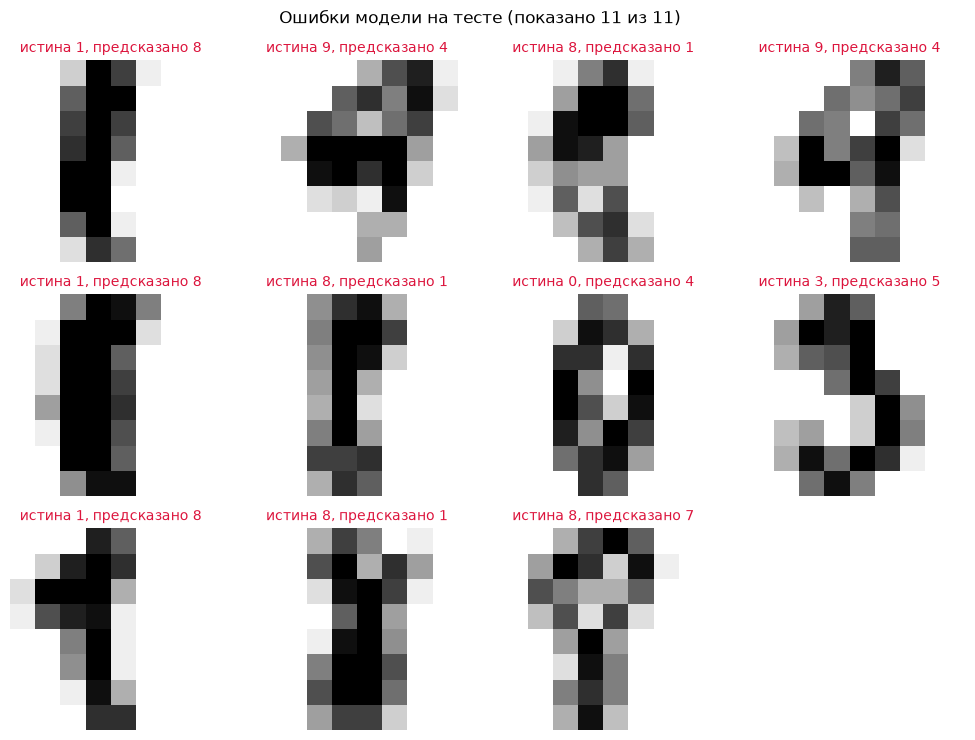

In [12]:
wrong = np.where(y_te_np != pred_te_np)[0]
show = wrong[:12]
fig, axes = plt.subplots(3, 4, figsize=(10, 7.5))
for ax in axes.ravel():
    ax.axis("off")
for ax, i in zip(axes.ravel(), show):
    ax.imshow((X_te[i] * 16).reshape(8, 8).numpy(), cmap="gray_r")
    ax.set_title(f"истина {y_te_np[i]}, предсказано {pred_te_np[i]}", fontsize=10, color="crimson")
fig.suptitle(f"Ошибки модели на тесте (показано {len(show)} из {len(wrong)})")
plt.tight_layout()
plt.show()

## 7. Сравнение с autograd и с моделями scikit-learn

### 7.1 Та же сеть на `torch.nn.Sequential` + `torch.optim.SGD`

Чтобы сравнение было честным, берём **те же начальные веса** (копия инициализации нашей сети), **тот же порядок мини-батчей** (генератор с тем же seed), те же `lr`, `momentum`, размер батча и число эпох. Отличие только одно: градиенты считает autograd, а шаг делает готовый оптимизатор PyTorch.

In [13]:
def to_sequential(init_net):
    # nn.Linear хранит веса как (out, in), у нашего Dense они (in, out) - транспонируем
    seq = torch.nn.Sequential(
        torch.nn.Linear(64, 64), torch.nn.ReLU(),
        torch.nn.Linear(64, 32), torch.nn.ReLU(),
        torch.nn.Linear(32, 10))
    linear = [m for m in seq if isinstance(m, torch.nn.Linear)]
    with torch.no_grad():
        for lin, dense in zip(linear, init_net.dense):
            lin.weight.copy_(dense.weights.T)
            lin.bias.copy_(dense.biases)
    return seq, linear


def fit_torch(model, optimizer, epochs, batch_size, seed, log_every=10):
    ce = torch.nn.CrossEntropyLoss()
    gen = torch.Generator().manual_seed(seed)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    n = X_tr.shape[0]
    for epoch in range(1, epochs + 1):
        perm = torch.randperm(n, generator=gen)
        for start in range(0, n, batch_size):
            idx = perm[start:start + batch_size]
            optimizer.zero_grad()
            loss = ce(model(X_tr[idx]), y_tr[idx])
            loss.backward()                              # градиенты считает autograd
            optimizer.step()
        with torch.no_grad():
            stats = []
            for X, y in ((X_tr, y_tr), (X_va, y_va)):
                out = model(X)
                stats.append((ce(out, y).item(), (out.argmax(dim=1) == y).float().mean().item()))
        (tl, ta), (vl, va) = stats
        for key, value in zip(hist, (tl, vl, ta, va)):
            hist[key].append(value)
        if log_every and (epoch == 1 or epoch % log_every == 0):
            print(f"эпоха {epoch:3d} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}")
    return hist


seq, linear = to_sequential(make_net(SEED))      # make_net(SEED) даёт ровно ту же инициализацию
opt_t = torch.optim.SGD(seq.parameters(), lr=LR, momentum=MOMENTUM)
hist_t = fit_torch(seq, opt_t, EPOCHS, BATCH, SEED)

with torch.no_grad():
    pred_t = seq(X_te).argmax(dim=1)
acc_t = (pred_t == y_te).float().mean().item()
print(f"\nAccuracy на test (nn.Sequential): {acc_t:.4f}")

w_diff = max(max((lin.weight.T - d.weights).abs().max().item(), (lin.bias - d.biases).abs().max().item())
             for lin, d in zip(linear, net.dense))
print(f"Максимальная разница весов после обучения: {w_diff:.3e}")
print(f"Объектов теста, на которых предсказания различаются: {int((pred_t != pred_te).sum())}")
print(f"Максимальная разница train loss по эпохам: {np.abs(np.array(hist['train_loss']) - np.array(hist_t['train_loss'])).max():.3e}")

эпоха   1 | train loss 0.5018 acc 0.8319 | val loss 0.5600 acc 0.8194
эпоха  10 | train loss 0.0318 acc 0.9870 | val loss 0.1129 acc 0.9667
эпоха  20 | train loss 0.0025 acc 1.0000 | val loss 0.0603 acc 0.9778
эпоха  30 | train loss 0.0014 acc 1.0000 | val loss 0.0589 acc 0.9806


эпоха  40 | train loss 0.0010 acc 1.0000 | val loss 0.0581 acc 0.9833
эпоха  50 | train loss 0.0007 acc 1.0000 | val loss 0.0594 acc 0.9833
эпоха  60 | train loss 0.0006 acc 1.0000 | val loss 0.0591 acc 0.9833

Accuracy на test (nn.Sequential): 0.9694
Максимальная разница весов после обучения: 1.281e-05
Объектов теста, на которых предсказания различаются: 0
Максимальная разница train loss по эпохам: 2.682e-07


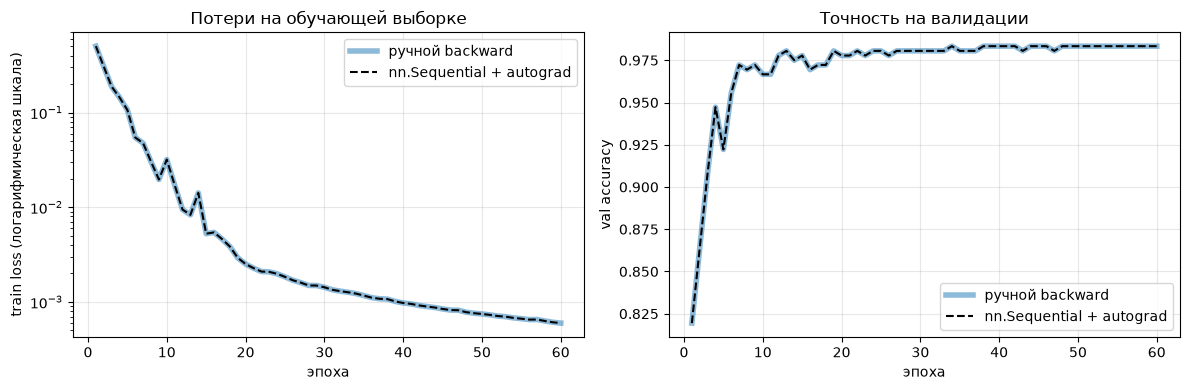

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_axis, hist["train_loss"], lw=4, alpha=0.5, label="ручной backward")
axes[0].plot(epochs_axis, hist_t["train_loss"], "k--", lw=1.5, label="nn.Sequential + autograd")
axes[0].set_yscale("log")
axes[0].set_xlabel("эпоха")
axes[0].set_ylabel("train loss (логарифмическая шкала)")
axes[0].set_title("Потери на обучающей выборке")
axes[0].legend()

axes[1].plot(epochs_axis, hist["val_acc"], lw=4, alpha=0.5, label="ручной backward")
axes[1].plot(epochs_axis, hist_t["val_acc"], "k--", lw=1.5, label="nn.Sequential + autograd")
axes[1].set_xlabel("эпоха")
axes[1].set_ylabel("val accuracy")
axes[1].set_title("Точность на валидации")
axes[1].legend()
plt.tight_layout()
plt.show()

### 7.2 Простые ориентиры из scikit-learn

Логистическая регрессия — линейная модель без скрытых слоёв (простой ориентир, с которым полезно сравнивать нейросеть). `MLPClassifier` — готовая нейросеть scikit-learn с похожей архитектурой (скрытые слои 64 и 32) и теми же параметрами SGD: momentum 0,9 без Нестерова, батч 32, `lr` 0,05, без L2-регуляризации, 60 эпох (раннюю остановку отключаем). Инициализация и порядок батчей у неё свои, поэтому точного совпадения с нашей сетью ждать не нужно.

In [15]:
Xtr_np, Xva_np, Xte_np = X_tr.numpy(), X_va.numpy(), X_te.numpy()
ytr_np, yva_np = y_tr.numpy(), y_va.numpy()

logreg = LogisticRegression(max_iter=2000).fit(Xtr_np, ytr_np)

mlp_sk = MLPClassifier(hidden_layer_sizes=(64, 32), solver="sgd", learning_rate_init=LR, momentum=MOMENTUM,
                       nesterovs_momentum=False, batch_size=BATCH, alpha=0.0, max_iter=EPOCHS,
                       n_iter_no_change=EPOCHS, random_state=SEED)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")        # предупреждение о том, что max_iter исчерпан
    mlp_sk.fit(Xtr_np, ytr_np)
print("MLPClassifier: выполнено эпох", mlp_sk.n_iter_)

with torch.no_grad():
    val_t = (seq(X_va).argmax(dim=1) == y_va).float().mean().item()
val_m = evaluate(net, X_va, y_va)[1]

summary = pd.DataFrame([
    {"модель": "Наша сеть (ручной backward)", "val accuracy": val_m, "test accuracy": acc_te},
    {"модель": "nn.Sequential + torch.optim.SGD", "val accuracy": val_t, "test accuracy": acc_t},
    {"модель": "sklearn MLPClassifier (64, 32)", "val accuracy": mlp_sk.score(Xva_np, yva_np),
     "test accuracy": mlp_sk.score(Xte_np, y_te_np)},
    {"модель": "sklearn LogisticRegression", "val accuracy": logreg.score(Xva_np, yva_np),
     "test accuracy": logreg.score(Xte_np, y_te_np)},
])
summary.round(4)

MLPClassifier: выполнено эпох 60


,модель,val accuracy,test accuracy
0,Наша сеть (ручной backward),0.9833,0.9694
1,nn.Sequential + torch.optim.SGD,0.9833,0.9694
2,"sklearn MLPClassifier (64, 32)",0.9694,0.9667
3,sklearn LogisticRegression,0.9722,0.9556


## 8. Влияние скорости обучения и размера батча

Проверяем несколько значений `lr`, размера батча и вариант без momentum на **валидационной** выборке (тест не трогаем). Для справки: при momentum $\mu$ шаг по «установившемуся» направлению примерно в $1/(1-\mu)$ раз больше, чем при $\mu=0$, поэтому `lr`=0,05 с $\mu=0{,}9$ сопоставим с `lr`=0,5 без momentum. Каждая конфигурация запускается с тремя разными seed (разные начальные веса и порядок батчей) и усредняется: в валидации 360 объектов, и один объект — это 0,28 п.п. accuracy, поэтому отдельный запуск шумный. Число эпох везде 60, то есть при меньшем батче шагов больше; поэтому эффект размера батча здесь смешан с числом шагов и с масштабом шага при том же `lr`. Колонка `std` — стандартное отклонение по трём seed (`np.std`, без поправки на малую выборку).

In [16]:
def run_config(lr, momentum, batch_size, seed):
    n = make_net(seed)
    h = fit(n, SGD(lr, momentum), EPOCHS, batch_size, seed, log_every=0)
    return h["train_loss"][-1], h["val_loss"][-1], h["val_acc"][-1]


configs = [  # (что меняем, lr, momentum, batch)
    ("основная", 0.05, 0.9, 32),
    ("lr", 0.005, 0.9, 32),
    ("lr", 0.01, 0.9, 32),
    ("lr", 0.2, 0.9, 32),
    ("batch", 0.05, 0.9, 8),
    ("batch", 0.05, 0.9, 128),
    ("без momentum", 0.05, 0.0, 32),
    ("без momentum", 0.5, 0.0, 32),
]

rows = []
for kind, lr, mom, bs in configs:
    res = np.array([run_config(lr, mom, bs, s) for s in (0, 1, 2)])
    rows.append({"что меняем": kind, "lr": lr, "momentum": mom, "batch": bs,
                 "train loss": res[:, 0].mean(), "val loss": res[:, 1].mean(),
                 "val acc, среднее": res[:, 2].mean(), "val acc, std": res[:, 2].std(),
                 "val acc по seed 0/1/2": " / ".join(f"{a:.3f}" for a in res[:, 2])})
experiments = pd.DataFrame(rows)
experiments.round(4)

,что меняем,lr,momentum,batch,train loss,val loss,"val acc, среднее","val acc, std",val acc по seed 0/1/2
0,основная,0.050,0.9,32,0.0006,0.0755,0.9824,0.0013,0.983 / 0.983 / 0.981
1,lr,0.005,0.9,32,0.0307,0.0992,0.9676,0.0047,0.969 / 0.972 / 0.961
2,lr,0.010,0.9,32,0.0100,0.0898,0.9741,0.0013,0.975 / 0.972 / 0.975
3,lr,0.200,0.9,32,1.0758,1.2228,0.5491,0.3535,0.100 / 0.964 / 0.583
4,batch,0.050,0.9,8,0.0080,0.1807,0.9713,0.0073,0.978 / 0.975 / 0.961
5,batch,0.050,0.9,128,0.0062,0.0973,0.9731,0.0026,0.969 / 0.975 / 0.975
6,без momentum,0.050,0.0,32,0.0305,0.0958,0.9685,0.0057,0.969 / 0.975 / 0.961
7,без momentum,0.500,0.0,32,0.0006,0.0784,0.9778,0.0023,0.981 / 0.975 / 0.978


## 9. Выводы

**Качество.**

- Сеть 64 → 64 → 32 → 10 (6570 параметров: 4160 + 2080 + 330) с ручным обратным распространением даёт на тестовой выборке accuracy **0,9694** (11 ошибок из 360). На обучающей выборке accuracy 1,0000, на валидационной 0,9833. Обучение занимает меньше секунды на CPU.
- Валидация (0,9833) и тест (0,9694) различаются на 5 объектов из 360. Один объект весит 0,28 п.п., так что такая разница укладывается в обычный разброс между выборками. Гиперпараметры по тесту не подбирались.

**Корректность обратного распространения.**

- Ручные градиенты совпали с `torch.autograd`: максимальная абсолютная разница по всем слоям $1{,}49\cdot10^{-8}$ в float32 (максимальные значения градиентов при этом 0,11–0,28) и $2{,}8\cdot10^{-17}$ в float64. Оба числа намного меньше порога $10^{-6}$, формулы (включая $(p-y)/N$ для softmax + кросс-энтропии) реализованы верно.
- Сеть с ручным backward и та же сеть на `nn.Sequential` + `torch.optim.SGD`, стартовавшие с одинаковых весов и с одинаковым порядком батчей, прошли практически одну траекторию. Кривые потерь отличаются не более чем на $2{,}7\cdot10^{-7}$, веса после 60 эпох — не более чем на $1{,}3\cdot10^{-5}$ (накопленное округление float32). Accuracy на тесте одинакова (0,9694), предсказания на всех 360 тестовых объектах совпали. Значит, и SGD с momentum реализован так же, как в PyTorch.

**Переобучение.**

- Train accuracy достигает 1,0 к 15-й эпохе, а val accuracy к концу обучения (60-я эпоха) равна 0,9833. Разрыв train/val равен 0,0167 (1,7 п.п.). Минимум val loss (0,0552) достигается на 21-й эпохе, к 60-й он равен 0,0591, то есть немного вырос, тогда как train loss продолжает падать (0,0025 на 20-й эпохе, 0,0006 на 60-й). Переобучение есть, но слабое: val accuracy при этом не снижается (0,9778 на 20-й эпохе, 0,9833 на 60-й). Регуляризацию и раннюю остановку мы не пробовали.

**Что показывает матрица ошибок.**

- Все 11 ошибок: «1 → 8» и «8 → 1» по 3 раза (вместе 6 из 11), «9 → 4» 2 раза, «0 → 4», «3 → 5» и «8 → 7» по одному разу. Поэтому слабее всего классы 8 (F1 = 0,899, recall = 0,886) и 1 (F1 = 0,917), а классы 2 и 6 распознаны без ошибок (F1 = 1,000). Precision класса 4 (0,923) снижена тремя объектами, которые сеть ошибочно отнесла к четвёркам (две девятки и один ноль).
- По картинкам ошибок видно, что часть «восьмёрок», принятых за «1», нарисована почти одним вертикальным штрихом. Это визуальное наблюдение, а не измеренный факт.

**Сравнение с другими моделями (test accuracy).**

- Наша сеть 0,9694, `nn.Sequential` 0,9694, `MLPClassifier` 0,9667, `LogisticRegression` 0,9556. Нейросети различаются на 1 объект, то есть практически одинаковы. Логистическая регрессия на тесте хуже на 5 объектов (около 1,4 п.п.), но на валидации она близка (0,9722 против 0,9833). Датасет простой: даже линейная модель даёт более 95 %. Преимущество нейросети здесь небольшое, и по одному разбиению строго доказать его нельзя.

**Влияние `lr`, размера батча и momentum (раздел 8, средняя val accuracy по трём seed).**

- `lr`: 0,005 → 0,9676; 0,01 → 0,9741; 0,05 → 0,9824; 0,2 → 0,5491. При малых `lr` за 60 эпох сеть не успевает сойтись (train loss 0,0307 и 0,0100 против 0,0006 при `lr` = 0,05). При `lr` = 0,2 обучение неустойчиво: val accuracy по seed равна 0,100 / 0,964 / 0,583. Скорее всего, шаг слишком велик, но отдельно это не проверялось.
- Размер батча: 8 → 0,9713, 128 → 0,9731 против 0,9824 при 32. Разница около 1 п.п. При батче 8 val loss заметно выше (0,1807 против 0,0755), вероятно из-за более шумного градиента. При батче 128 за те же 60 эпох делается меньше шагов, и train loss выше (0,0062 против 0,0006).
- Momentum ускоряет сходимость: без него при `lr` = 0,05 val accuracy 0,9685 и train loss 0,0305, а при `lr` = 0,5 (сопоставимый по величине шаг) val accuracy 0,9778 и train loss 0,0006, что близко к основной конфигурации.
- Различия между рабочими конфигурациями составляют 1–1,5 п.п. (3–5 объектов валидации) при трёх seed, поэтому их надо читать осторожно. Уверенный вывод только один: слишком малый `lr` замедляет обучение, а слишком большой (0,2 при momentum 0,9) делает его неустойчивым.

**Что не проверялось.** Устойчивость результата на других разбиениях (кросс-валидация), регуляризация и ранняя остановка, другие архитектуры и методы оптимизации. Все выводы относятся к одному разбиению `random_state=42` и небольшому датасету 8×8.